# PS8: Object detection with YOLOv8 on fruit images
Dataset: https://www.kaggle.com/datasets/afsananadia/fruits-images-dataset-object-detection
Layout: "Train File/Train File" and "Test File/Test File", each with images and YOLO .txt box labels.
Every label file uses class 0, so the real class is taken from the file name (e.g. 05_Banana.jpg -> banana).

Install once: `pip install ultralytics`

In [1]:
import random
import shutil
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
from ultralytics import YOLO

SRC = Path("../datasets/fruits-images-dataset")
OUT = Path("fruits_yolo")
EPOCHS = 30
ALIASES = {"hogpulm": "hogplum", "lichi": "litchi"}

In [2]:
def key(path):
    return path.stem.lower().replace(" ", "")


def fruit(path):
    name = key(path).split("_", 1)[1]
    return ALIASES.get(name, name)


pairs = {}
for split, folder in [("train", "Train File"), ("val", "Test File")]:
    files = list((SRC / folder).rglob("*"))
    labels = {key(f): f for f in files if f.suffix == ".txt"}
    pairs[split] = [(img, labels[key(img)]) for img in files
                    if img.suffix.lower() in (".jpg", ".jpeg", ".png") and key(img) in labels]
classes = sorted({fruit(img) for items in pairs.values() for img, _ in items})
print("Classes:", classes)
for split, items in pairs.items():
    print(split, len(items), dict(Counter(fruit(img) for img, _ in items)))

Classes: ['apple', 'banana', 'grapes', 'guava', 'hogplum', 'jackfruit', 'litchi', 'mango', 'orange', 'papaya']
train 320 {'apple': 32, 'banana': 32, 'grapes': 32, 'guava': 32, 'hogplum': 32, 'jackfruit': 32, 'litchi': 32, 'mango': 32, 'orange': 32, 'papaya': 32}
val 80 {'apple': 8, 'banana': 8, 'grapes': 8, 'guava': 8, 'hogplum': 8, 'jackfruit': 8, 'litchi': 8, 'mango': 8, 'orange': 8, 'papaya': 8}


In [3]:
for split, items in pairs.items():
    for d in ("images", "labels"):
        (OUT / d / split).mkdir(parents=True, exist_ok=True)
    for i, (img, label) in enumerate(items):
        name = f"{i:04d}_{key(img)}"
        cls = classes.index(fruit(img))
        lines = [f"{cls} " + " ".join(l.split()[1:]) for l in label.read_text().splitlines() if l.strip()]
        shutil.copy(img, OUT / "images" / split / f"{name}{img.suffix.lower()}")
        (OUT / "labels" / split / f"{name}.txt").write_text("\n".join(lines))

yaml_path = OUT / "data.yaml"
yaml_path.write_text(
    f"path: {OUT.resolve().as_posix()}\ntrain: images/train\nval: images/val\nnames:\n"
    + "".join(f"  {i}: {c}\n" for i, c in enumerate(classes)))
print(yaml_path.read_text())

path: C:/Users/choud/OneDrive/Desktop/deep learning/endsem/PS08_YOLO_Fruit_Detection/fruits_yolo
train: images/train
val: images/val
names:
  0: apple
  1: banana
  2: grapes
  3: guava
  4: hogplum
  5: jackfruit
  6: litchi
  7: mango
  8: orange
  9: papaya



In [4]:
model = YOLO("yolov8n.pt")
model.train(data=str(yaml_path), epochs=EPOCHS, imgsz=640, seed=42)
save_dir = Path(model.trainer.save_dir)

Ultralytics 8.4.212  Python-3.10.11 torch-2.10.0+cpu CPU (11th Gen Intel Core i7-11800H @ 2.30GHz)


engine\trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=fruits_yolo\data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=30, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train, nbs=64, nms=None, opset=None, optimize=False, optimizer=auto, overlap_mask=True, patience=100, perspective=0.0, plots=True, pose=12.0, pretraine

Overriding model.yaml nc=80 with nc=10



                   from  n    params  module                                       arguments                     


  0                  -1  1       464  ultralytics.nn.modules.conv.Conv             [3, 16, 3, 2]                 


  1                  -1  1      4672  ultralytics.nn.modules.conv.Conv             [16, 32, 3, 2]                


... (836 outputs left out)

                orange          8          8      0.122      0.375      0.159      0.122


                papaya          8          8      0.357      0.625      0.371      0.226


Speed: 1.0ms preprocess, 38.4ms inference, 0.0ms loss, 0.8ms postprocess per image


Results saved to C:\Users\choud\OneDrive\Desktop\deep learning\endsem\PS08_YOLO_Fruit_Detection\runs\detect\train


Ultralytics 8.4.212  Python-3.10.11 torch-2.10.0+cpu CPU (11th Gen Intel Core i7-11800H @ 2.30GHz)


Model summary (fused): 73 layers, 3,134,894 parameters, 0 gradients, 8.6 GFLOPs


val: Fast image access  (ping: 0.1±0.0 ms, read: 1088.6±611.6 MB/s, size: 1244.5 KB)


val: Scanning C:\Users\choud\OneDrive\Desktop\deep learning\endsem\PS08_YOLO_Fruit_Detection\fruits_yolo\labels\val.cache... 80 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 80/80  0.0s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 20% ━━────────── 1/5 2.2s/it 0.6s<8.6s

                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 40% ━━━━╸─────── 2/5 2.0s/it 2.5s<6.1s

... (13 outputs left out)

                papaya          8          8       0.28        0.5      0.327      0.231


Speed: 1.5ms preprocess, 35.9ms inference, 0.0ms loss, 0.8ms postprocess per image


Results saved to C:\Users\choud\OneDrive\Desktop\deep learning\endsem\PS08_YOLO_Fruit_Detection\runs\detect\val


Precision: 0.2946  Recall: 0.4617
mAP@0.5: 0.3002  mAP@0.5:0.95: 0.2055


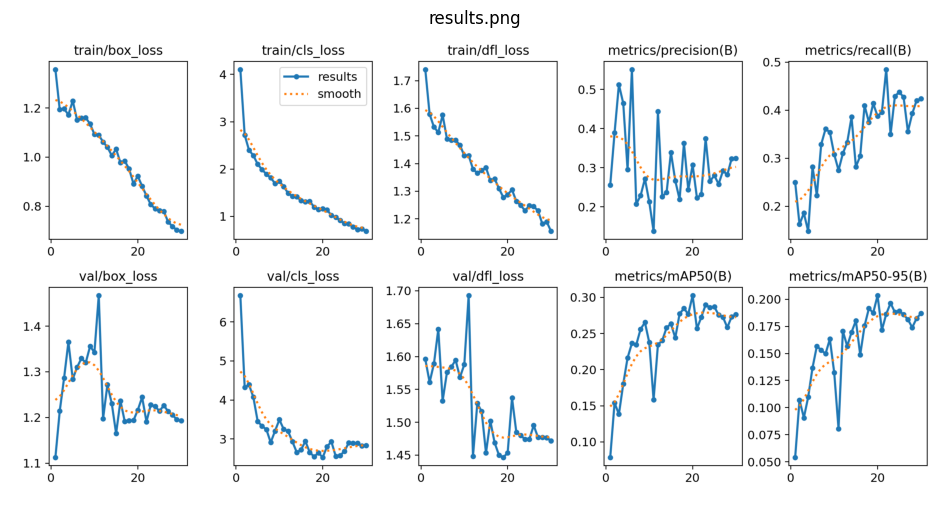

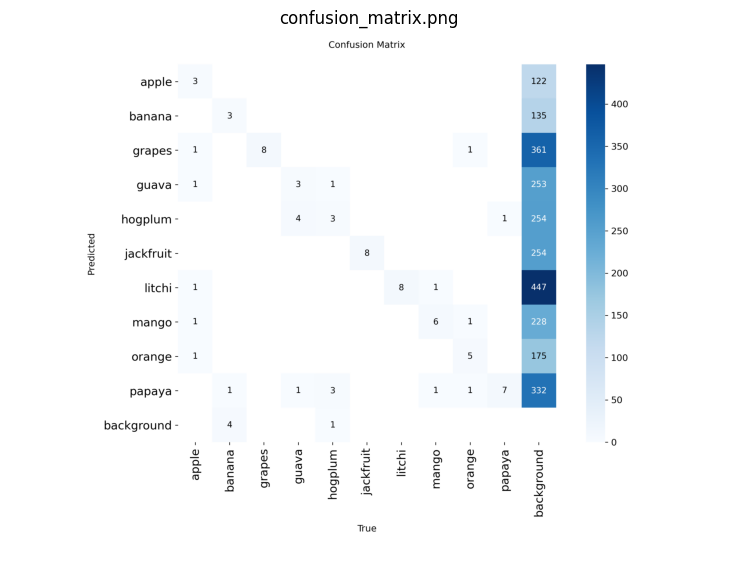

In [5]:
metrics = model.val(data=str(yaml_path))
print(f"Precision: {metrics.box.mp:.4f}  Recall: {metrics.box.mr:.4f}")
print(f"mAP@0.5: {metrics.box.map50:.4f}  mAP@0.5:0.95: {metrics.box.map:.4f}")

for name in ["results.png", "confusion_matrix.png"]:
    plt.figure(figsize=(12, 7))
    plt.imshow(plt.imread(save_dir / name))
    plt.title(name)
    plt.axis("off")
    plt.show()

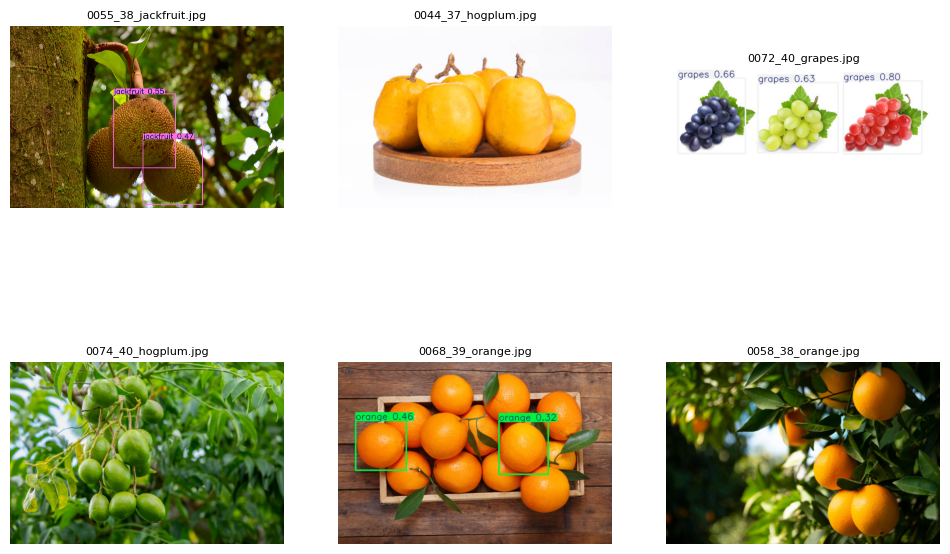

In [6]:
val_images = sorted((OUT / "images" / "val").glob("*"))
plt.figure(figsize=(12, 8))
for i, img in enumerate(random.sample(val_images, min(6, len(val_images)))):
    r = model.predict(str(img), conf=0.25, verbose=False)[0]
    plt.subplot(2, 3, i + 1)
    plt.imshow(r.plot()[..., ::-1])
    plt.title(img.name, fontsize=8)
    plt.axis("off")
plt.show()